# Sprint 2: features and modelling

**Parfois product similarity, MADSAD case study (FEP, University of Porto).**

Sprint 1 produced a clean table with one row per colourway (`outputs/phase1/items_clean.csv`). This notebook does
the two parts of Sprint 2:

- **Features** (sections 1–10): each colourway becomes **numbers that can be compared**, one *block* of features per
  kind of information, so that the similarity of two products is computed block by block and can be explained
  ("same family", "same materials", "similar photo").
- **Modelling** (sections 11–16): the blocks are combined into **one similarity score**, the model is evaluated
  without a ground truth, and its weights are chosen first on automatic signals and then on the team's own judgement.

Every step that runs on a laptop is **written out here** with pandas, NumPy and Pillow. Three steps were not done in
this notebook; they are **described**, and their saved results are loaded:

- the **text embedding** of each product description (sentence model all-MiniLM-L6-v2), run once;
- the **image embedding** of each photo (CLIP ViT-B/32), run once;
- the team's **sorting of candidates** in a browser app (`outputs/phase4/feedback_*.jsonl`), used to learn the weights.

| Section | Block | How |
|---|---|---|
| 1 | — | Input and the common rule of every block |
| 2 | categorical | weighted one-hot of the product attributes |
| 3 | composition | materials, weighted by rarity |
| 4 | numeric | price within the category, launch date, season |
| 5 | — | filling missing material and metal, only where it is reliable |
| 6 | text | sentence embedding of a description (loaded) |
| 7 | image | CLIP embedding of the product crop (loaded) |
| 8 | palette | dominant colours of each photo (k-means in LAB) |
| 9 | — | colour names measured on the photos |
| 10 | — | the blocks side by side on one product |
| 11 | model | one score: the weighted mean of the block similarities, like-for-like candidates |
| 12 | evaluation | signals without a ground truth, tuning and test halves, random baseline |
| 13 | weights | step 1: guarded search on the signals; the photo-vs-attributes trade-off |
| 14 | weights | step 2: learned from the team's sorting (Bradley–Terry), blended 25% |
| 15 | model | the final model: top 10 for every colourway, results, ablations |
| 16 | — | the example of the brief, and why each match was chosen |

The notebook writes no file. Running time: about 8 minutes (the palettes read every photo; the weight search runs the
model about 30 times).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR, EMB_DIR = ROOT / "data" / "images", ROOT / "data" / "embeddings"
KEY = "PROD_CLR_EQUIV"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. Input and the common rule

The input is the result of Sprint 1. Codes are read as text, so leading zeros survive.

In [2]:
CODES = {c: str for c in ["PROD_REF", "PROD_REF_EQUIV", "SEA_COD", "CAT_COD", "GFA_COD", "GFS_COD"]}
items = pd.read_csv(ROOT / "outputs" / "phase1" / "items_clean.csv", encoding="utf-8-sig", dtype=CODES, low_memory=False)
items["STORE_DATE_FINAL"] = pd.to_datetime(items["STORE_DATE_FINAL"])
for c in ["img_trusted", "img_colour_trusted"]:
    items[c] = items[c].astype(str).eq("True")
items = items.sort_values(KEY, kind="stable").reset_index(drop=True)
print(f"{len(items):,} colourways x {items.shape[1]} columns | photos trusted: {items['img_trusted'].sum():,}")
items[[KEY, "CAT_DES_EN", "GFA_DES_EN", "GFS_DES_EN", "CLR_DES", "FINISHING", "COMPOSITION", "PRICE_BASE_W_VAT"]].head()

10,555 colourways x 116 columns | photos trusted: 9,445


,PROD_CLR_EQUIV,CAT_DES_EN,GFA_DES_EN,GFS_DES_EN,CLR_DES,FINISHING,COMPOSITION,PRICE_BASE_W_VAT
0,1328502PM,Jewellery,Rings,Cocktail,Pastel Multicolor,Worn Gold,Stone; Zinc,8.99
1,140428_BN,Jewellery,Necklaces,Pendant,Silver,Other,NaN,9.99
2,1404862PE,Jewellery,Key chains,Figures,Pearl,Rodhium,Acrylic; Crystal Glass; Iron; Zinc,12.99
3,140486_BM,Jewellery,Key chains,Figures,Bright Multicolor,Golden,Acrylic; Crystal Glass; Iron; Zinc,12.99
4,140486_HM,Jewellery,Key chains,Figures,Halftone Multicolor,NaN,Crystal Glass; Iron; Zinc,9.99


**The rule every block follows.** Each product becomes a row of numbers of **length 1** (L2-normalised). The
similarity of two products in a block is then the dot product of their rows, the *cosine similarity*: 1 for
identical rows, 0 for nothing in common.

A block is also split into named **attributes** (groups of columns). The dot product of two rows is the sum of the
dot products of their attribute slices, so the score can be **explained**: e.g. 0.42 from the family, 0.20 from
the colour. A missing value is a row of zeros: it never counts as a match.

In [3]:
def normalise_rows(m):
    norms = np.linalg.norm(m, axis=1, keepdims=True)
    return np.divide(m, norms, out=np.zeros_like(m), where=norms > 0).astype(np.float32)

def shared_attributes(m, attrs, i, j):
    """How much each attribute adds to the similarity of rows i and j (the parts add up to the score)."""
    out = {}
    for name, (start, stop) in attrs.items():
        part = float(m[i, start:stop] @ m[j, start:stop])
        if part > 1e-6:
            out[name] = round(part, 3)
    return dict(sorted(out.items(), key=lambda kv: -kv[1]))

def neighbours(m, i, k=4, same_category=True):
    """Top k rows by cosine similarity: same category, other models only (another colour of the same model is
    trivially similar)."""
    s = m @ m[i]
    if same_category:
        s[(items["CAT_DES_EN"] != items["CAT_DES_EN"].iat[i]).to_numpy()] = -1
    s[(items["PROD_REF"] == items["PROD_REF"].iat[i]).to_numpy()] = -1
    top = np.argsort(-s, kind="stable")[:k]
    return top, s[top]

## 2. Categorical block

Each attribute is one-hot encoded, and each attribute gets a **weight** saying how much it matters for a buyer.
The value stored is √weight, so two products score the **sum of the weights they share** (before normalising).

Family (`GFA`) and sub-family (`GFS`) are encoded as **paths** (`Jewellery › Earrings › Hoop Earrings`), because names
such as "Others" repeat across categories and only mean something below their parent.

`FINISH_FAMILY` groups the ~30 finishing names into gold / rose gold / silver / black / other, so that "Golden" and
"Worn Gold" still get partial credit.

In [4]:
FINISH_FAMILY = {
    "gold": ["Golden", "Worn Gold", "Brushed Golden", "Antik Golden", "Gold Plated", "Matte Golden", "Burnish Golden",
             "Light Golden", "Worn Yellow Gold", "Matt Brushed Gold", "Scratched Gold"],
    "rose gold": ["Rose Gold", "Brushed Rose Gold", "Worn Rose God"],
    "silver": ["Rodhium", "Silver", "Worn Rhodium", "Worn Silver", "Brushed Silver", "Antik Silver", "Brushed Rhodium",
               "Matte Silver", "Silver Plated"],
    "black": ["Black Nikel", "Black Plating"],
    "other": ["Other", "Multifinishing", "Cooper"],
}
FAMILY_OF = {v: fam for fam, vals in FINISH_FAMILY.items() for v in vals}
items["FINISH_FAMILY"] = items["FINISHING"].map(FAMILY_OF)

# attribute -> (source columns forming a path, weight)
CATEGORICAL = {
    "CAT": (["CAT_DES_EN"], 1.0),
    "GFA": (["CAT_DES_EN", "GFA_DES_EN"], 3.0),
    "GFS": (["CAT_DES_EN", "GFA_DES_EN", "GFS_DES_EN"], 3.0),
    "CATEGORY_MATRIX": (["CATEGORY_MATRIX"], 1.5),
    "CLR_DES": (["CLR_DES"], 2.0),
    "CLR_TYPE": (["CLR_TYPE"], 0.5),
    "FINISHING": (["FINISHING"], 1.5),
    "FINISH_FAMILY": (["FINISH_FAMILY"], 1.0),
    "MATERIAL": (["MATERIAL"], 1.0),
    "PRINT_TYPE": (["PRINT_TYPE"], 1.0),
    "DIMENSION": (["DIMENSION"], 1.0),
    "OUTFIT": (["OUTFIT"], 1.0),
    "THEME": (["THEME"], 1.5),
    "FASHIONTYPE": (["FASHIONTYPE"], 0.5),
    "PROD_SEG": (["PROD_SEG"], 0.5),
    "NUMBER_OF_UNITS": (["NUMBER_OF_UNITS"], 0.5),
}

def categorical_block(df, spec=CATEGORICAL):
    parts, attrs, start = [], {}, 0
    for name, (cols, weight) in spec.items():
        values = df[cols[0]].astype("string")
        for c in cols[1:]:
            values = values + " › " + df[c].astype("string")       # missing if any part is missing
        levels = sorted(values.dropna().unique())
        codes = pd.Categorical(values, categories=levels).codes
        onehot = np.zeros((len(df), len(levels)), np.float32)
        onehot[np.flatnonzero(codes >= 0), codes[codes >= 0]] = np.sqrt(weight)
        parts.append(onehot)
        attrs[name] = (start, start + len(levels))
        start += len(levels)
    return normalise_rows(np.hstack(parts)), attrs

How filled and how varied each attribute is (before the missing values of section 5 are filled):

In [5]:
summary = pd.DataFrame({name: {"columns": " › ".join(cols), "weight": w,
                               "values": items[cols].dropna().drop_duplicates().shape[0],
                               "filled": items[cols].notna().all(axis=1).mean()}
                        for name, (cols, w) in CATEGORICAL.items()}).T
summary.style.format({"filled": "{:.0%}"})

,columns,weight,values,filled
CAT,CAT_DES_EN,1.000000,5,100%
GFA,CAT_DES_EN › GFA_DES_EN,3.000000,67,100%
GFS,CAT_DES_EN › GFA_DES_EN › GFS_DES_EN,3.000000,416,100%
CATEGORY_MATRIX,CATEGORY_MATRIX,1.500000,101,98%
CLR_DES,CLR_DES,2.000000,99,100%
CLR_TYPE,CLR_TYPE,0.500000,3,100%
FINISHING,FINISHING,1.500000,28,48%
FINISH_FAMILY,FINISH_FAMILY,1.000000,5,48%
MATERIAL,MATERIAL,1.000000,26,13%
PRINT_TYPE,PRINT_TYPE,1.000000,19,100%


## 3. Composition block

`COMPOSITION` lists the materials (`"Brass; Glass; Zinc"`). Each material is one column, weighted by its **rarity**
(IDF, as in text search): sharing "Pearl" says more than sharing "Polyester", which half the apparel has.

IDF = log((1 + N) / (1 + products with the material)) + 1

In [6]:
def composition_block(df):
    tokens = df["COMPOSITION"].fillna("").map(lambda s: sorted({t.strip() for t in str(s).split(";") if t.strip()}))
    vocab = sorted({t for ts in tokens for t in ts})
    col = {t: j for j, t in enumerate(vocab)}
    counts = pd.Series([t for ts in tokens for t in ts]).value_counts()
    idf = {t: float(np.log((1 + len(df)) / (1 + counts[t])) + 1) for t in vocab}
    m = np.zeros((len(df), len(vocab)), np.float32)
    for i, ts in enumerate(tokens):
        for t in ts:
            m[i, col[t]] = idf[t]
    return normalise_rows(m), {t: (j, j + 1) for t, j in col.items()}, counts, idf

comp, comp_attrs, counts, idf = composition_block(items)
print(f"{len(comp_attrs)} materials")
mat = pd.DataFrame({"products": counts, "weight (IDF)": pd.Series(idf).round(2)}).sort_values("products", ascending=False)
mat.iloc[list(range(6)) + list(range(-4, 0))]   # the most and the least common

95 materials


,products,weight (IDF)
Polyester,4312,1.90
Polyurethane,3273,2.17
Zinc,2444,2.46
Iron,2034,2.65
Thermoplastic Polyurethane,1194,3.18
Brass,1154,3.21
Pig leather,1,9.57
PROPIONIC ACID,1,9.57
Rattan,1,9.57
Vinyl,1,9.57


## 4. Numeric block

- **Price**, compared **within the category** (a 30 € bag is cheap, a 30 € ring is not): its percentile in the
  category, 0 to 1.
- **Launch date** (`STORE_DATE_FINAL`): months since the first launch.
- **Season** (`SEA_COD`): one-hot.

A number cannot simply be one column in a cosine similarity, so price and date are encoded as **soft bands**:
Gaussian bumps at regular centres. Two products then score about exp(−Δ² / 4σ²): close values ≈ 1, far values ≈ 0.
Weights inside the block: price 2, launch 1, season 0.5.

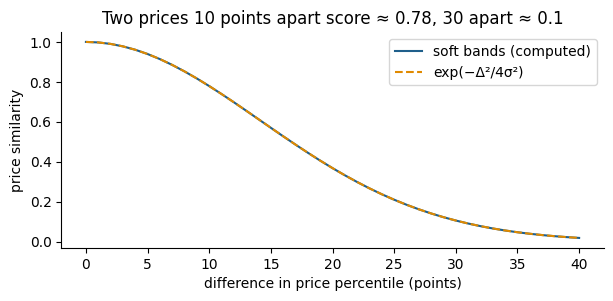

In [7]:
PRICE_SIGMA, LAUNCH_SIGMA = 0.10, 1.5          # in percentile points / in months
NUMERIC = {"price": 2.0, "launch": 1.0, "season": 0.5}

def soft_bands(x, centres, sigma):
    m = np.exp(-((x[:, None] - centres[None, :]) ** 2) / (2 * sigma ** 2)).astype(np.float32)
    m[np.isnan(x)] = 0
    return normalise_rows(m)

def numeric_block(df):
    price_pct = df.groupby("CAT_DES_EN")["PRICE_BASE_W_VAT"].rank(pct=True, method="average").to_numpy(float)
    months = ((df["STORE_DATE_FINAL"] - df["STORE_DATE_FINAL"].min()).dt.days / 30.44).to_numpy(float)
    # centres run 3σ past both ends, so values at the edges are compared like the others
    price_c = np.arange(-3 * PRICE_SIGMA, 1 + 3 * PRICE_SIGMA + 1e-9, PRICE_SIGMA / 2)
    launch_c = np.arange(np.floor(np.nanmin(months) - 3 * LAUNCH_SIGMA), np.ceil(np.nanmax(months) + 3 * LAUNCH_SIGMA) + 1e-9,
                         LAUNCH_SIGMA / 2)
    seasons = sorted(df["SEA_COD"].dropna().unique())
    codes = pd.Categorical(df["SEA_COD"], categories=seasons).codes
    season = np.zeros((len(df), len(seasons)), np.float32)
    season[np.flatnonzero(codes >= 0), codes[codes >= 0]] = 1
    parts = {"price": soft_bands(price_pct, price_c, PRICE_SIGMA), "launch": soft_bands(months, launch_c, LAUNCH_SIGMA),
             "season": season}
    attrs, start = {}, 0
    for name, m in parts.items():
        attrs[name] = (start, start + m.shape[1])
        start += m.shape[1]
    return normalise_rows(np.hstack([m * np.float32(np.sqrt(NUMERIC[n])) for n, m in parts.items()])), attrs

d = np.linspace(0, 0.4, 41)
centres = np.arange(-0.3, 1.3 + 1e-9, 0.05)
a = soft_bands(np.full(len(d), 0.5), centres, PRICE_SIGMA)
b = soft_bands(0.5 + d, centres, PRICE_SIGMA)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(d * 100, (a * b).sum(1), color="#1f5f8b", label="soft bands (computed)")
ax.plot(d * 100, np.exp(-d ** 2 / (4 * PRICE_SIGMA ** 2)), "--", color="#e08a00", label="exp(−Δ²/4σ²)")
ax.set_xlabel("difference in price percentile (points)")
ax.set_ylabel("price similarity")
ax.set_title("Two prices 10 points apart score ≈ 0.78, 30 apart ≈ 0.1")
ax.legend()
plt.show()

## 5. Filling missing material and metal, only where it is reliable

Two attributes buyers care about are often empty:

- `MATERIAL` (apparel only): the main fabric;
- the **metal** of jewellery (`FINISH_FAMILY`: gold, silver…).

They are filled **only for products with a trusted photo, and only when the guess is reliable**. The original values
are never replaced. Methods, in order:

1. **sibling** (material): another colour of the same model has a material (they agree 99.7% of the time);
2. **composition** (material): the composition is a single material that is also a `MATERIAL` value;
3. **neighbours**: a vote of the 15 most similar products of the category, weighted by similarity, kept when the
   winner has at least 80% of the votes. For the metal, the photo must agree: "gold" only if the colour palette is
   yellowish (mean b* ≥ 3), "silver" only if it is not (b* ≤ 6). Gold is 79% of the jewellery, so without this check
   silver items would too often be called gold.

Similarity for the vote: categorical block **without the attributes being guessed**, composition, CLIP image
embedding and colour palette (both loaded from `data/embeddings/`, see sections 7–8).

How reliable is each value? **5-fold cross-validation** on the products that do have it, with folds by model, so that
colours of the same model never help each other. A value is filled by the neighbours only if its precision is at least
90% on at least 10 predictions.

In [8]:
def aligned(npy, meta_json):
    keys = json.loads((EMB_DIR / meta_json).read_text(encoding="utf-8"))["keys"]
    emb = np.load(EMB_DIR / npy).astype(np.float32)
    idx = items[KEY].map(pd.Series(range(len(keys)), index=keys))
    out = np.zeros((len(items), emb.shape[1]), np.float32)
    ok = idx.notna().to_numpy()
    out[ok] = emb[idx[ok].astype(int).to_numpy()]
    return out

image_raw = aligned("image_clip.npy", "image_clip.json")
palettes_saved = pd.read_parquet(EMB_DIR / "palettes.parquet").set_index(KEY)
palette_raw = np.stack([np.asarray(v, np.float32) if isinstance(v, (list, np.ndarray)) else np.zeros(24, np.float32)
                        for v in items[KEY].map(palettes_saved["palette_vector"])])
image_raw[~items["img_trusted"].to_numpy()] = 0
palette_raw[~items["img_trusted"].to_numpy()] = 0
yellow = items[KEY].map(pd.Series([sum(s * c[2] for s, c in zip(sh, lab)) for sh, lab in
                                   zip(palettes_saved["shares"], palettes_saved["lab"])], index=palettes_saved.index)).to_numpy()

VOTE_WEIGHTS = {"MATERIAL": {"categorical": 1.0, "composition": 3.0, "image": 1.0, "palette": 0.5},
                "FINISH_FAMILY": {"categorical": 1.0, "composition": 1.0, "image": 2.0, "palette": 2.0}}

def vote_features(target):
    spec = {k: v for k, v in CATEGORICAL.items() if k not in ("FINISHING", "MATERIAL", "FINISH_FAMILY")}
    parts = {"categorical": categorical_block(items, spec)[0], "composition": comp, "image": image_raw, "palette": palette_raw}
    w = VOTE_WEIGHTS[target]
    return normalise_rows(np.hstack([m * np.float32(np.sqrt(w[n])) for n, m in parts.items()]))

def knn_vote(Xq, Xt, yt, k=15):
    pred, conf = np.empty(len(Xq), dtype=object), np.zeros(len(Xq))
    for s in range(0, len(Xq), 512):
        sim = Xq[s:s + 512] @ Xt.T
        top = np.argsort(-sim, axis=1, kind="stable")[:, :k]
        for i, row in enumerate(top):
            votes = pd.Series(np.clip(sim[i, row], 0, None)).groupby(yt[row]).sum()
            if votes.sum() > 0:
                best = votes.sort_index().idxmax()
                pred[s + i], conf[s + i] = best, votes[best] / votes.sum()
    return pred, conf

def photo_agrees(pred, yel):
    pred, yel = np.asarray(pred, dtype=object), np.asarray(yel, float)
    return ~(((pred == "gold") & ~(yel >= 3.0)) | ((pred == "silver") & (yel > 6.0)))

In [9]:
TARGETS = {"MATERIAL": "Apparel", "FINISH_FAMILY": "Jewellery"}
filled, evidence = [], {}
for col, cat in TARGETS.items():
    X = vote_features(col)
    in_cat = items["CAT_DES_EN"].eq(cat)
    lab = (in_cat & items[col].notna()).to_numpy()
    y, groups = items.loc[lab, col].to_numpy(), items.loc[lab, "PROD_REF"].to_numpy()

    # cross-validation, folds by model
    rng = np.random.default_rng(0)
    models = np.unique(groups)
    fold = pd.Series(rng.integers(0, 5, len(models)), index=models).loc[groups].to_numpy()
    pred, conf = np.empty(len(y), dtype=object), np.zeros(len(y))
    for f in range(5):
        pred[fold == f], conf[fold == f] = knn_vote(X[lab][fold == f], X[lab][fold != f], y[fold != f])
    ok_photo = photo_agrees(pred, yellow[lab]) if col == "FINISH_FAMILY" else np.ones(len(y), bool)
    kept = (conf >= 0.8) & ok_photo
    prec = pd.Series(pred[kept] == y[kept]).groupby(pred[kept]).agg(["mean", "size"])
    allowed = set(prec.index[(prec["mean"] >= 0.9) & (prec["size"] >= 10)])
    evidence[col] = {"products with the value": len(y), "accuracy (all)": (pred == y).mean(),
                     "share kept (vote ≥ 80%)": kept.mean(), "accuracy (kept)": (pred == y)[kept].mean(),
                     "values allowed": ", ".join(sorted(allowed))}

    # fill: trusted photo, value missing
    todo = in_cat & items[col].isna() & items["img_trusted"]
    guess = pd.Series(np.nan, index=items.index[todo], dtype=object)
    method = pd.Series("", index=guess.index)
    if col == "MATERIAL":
        vocab = set(items.loc[in_cat, col].dropna())
        sib = items[items[col].notna()].groupby("PROD_REF")[col].agg(lambda s: s.iloc[0] if s.nunique() == 1 else np.nan)
        single = items["COMPOSITION"].fillna("").map(
            lambda s: [t.strip() for t in s.split(";") if t.strip()]).map(lambda t: t[0] if len(t) == 1 and t[0] in vocab else np.nan)
        for name, values in (("sibling", items["PROD_REF"].map(sib)), ("composition", single)):
            free = guess.isna() & values.loc[guess.index].notna()
            guess[free], method[free] = values.loc[guess.index[free]], name
    free = guess.index[guess.isna()]
    p, c = knn_vote(X[free.to_numpy()], X[lab], y)
    keep = (c >= 0.8) & np.isin(p, list(allowed))
    if col == "FINISH_FAMILY":
        keep &= photo_agrees(p, yellow[free.to_numpy()])
    guess[free[keep]], method[free[keep]] = p[keep], "neighbours"
    done = guess.notna()
    filled.append(pd.DataFrame({KEY: items.loc[guess.index[done], KEY], "column": col, "value": guess[done],
                                "method": method[done]}))
filled = pd.concat(filled, ignore_index=True)
pd.DataFrame(evidence).T

,products with the value,accuracy (all),share kept (vote ≥ 80%),accuracy (kept),values allowed
MATERIAL,1303,0.785879,0.655411,0.923888,"Cotton, Lyocell, Polyester, Viscose"
FINISH_FAMILY,4154,0.866875,0.616273,0.965234,"gold, other, silver"


In [10]:
print(filled.groupby(["column", "method"]).size().rename("values filled").to_string())
for col in TARGETS:
    sub = filled[filled["column"] == col].set_index(KEY)["value"]
    items[col] = items[col].where(items[col].notna(), items[KEY].map(sub))
print("\nfilled now:", {col: f"{items.loc[items['CAT_DES_EN'] == cat, col].notna().mean():.0%} of {cat}"
                        for col, cat in TARGETS.items()})

column         method     
FINISH_FAMILY  neighbours     266
MATERIAL       composition    324
               neighbours     195
               sibling         61

filled now: {'MATERIAL': '83% of Apparel', 'FINISH_FAMILY': '95% of Jewellery'}


Not filled on purpose: the detailed finishing (golden vs worn gold vs brushed golden…) and the finishing of hand
bags, because the neighbours get them right too rarely.

With the filled values, the three tabular blocks are built:

In [11]:
cat_m, cat_attrs = categorical_block(items)
num_m, num_attrs = numeric_block(items)
print(f"categorical {cat_m.shape} | composition {comp.shape} | numeric {num_m.shape}")

categorical (10555, 1624) | composition (10555, 95) | numeric (10555, 79)


## 6. Text block (computed once, loaded here)

The categorical block only matches **identical** labels: "Golden Basics" and "GOLDEN DELICATES", or "Hoop Earrings" and
"Huggie", count as different. A sentence model knows they are close.

For each product a short English description is **built from the reviewed attributes** (never from the photo):

In [12]:
def clean(v):
    return "" if pd.isna(v) else str(v).strip()

def describe(r):
    theme = clean(r["THEME"])
    theme = theme.title() if theme.isupper() else theme
    finish = f"Finish: {clean(r['FINISHING'])}. " if clean(r["FINISHING"]) else ""
    material = f"Made of {clean(r['COMPOSITION']).replace(';', ',')}. " if clean(r["COMPOSITION"]) else ""
    prt = f"Print: {clean(r['PRINT_TYPE'])}. " if clean(r["PRINT_TYPE"]) not in ("", "No Print") else ""
    return (f"{clean(r['GFS_DES_EN'])} ({clean(r['GFA_DES_EN'])}, {clean(r['CAT_DES_EN'])}). "
            f"Colour: {clean(r['CLR_DES']) or 'unknown'}. {finish}{material}{prt}Theme: {theme or 'none'}. "
            f"{clean(r['FASHIONTYPE'])}, {clean(r['PROD_SEG'])}.").strip()

text_meta = json.loads((EMB_DIR / "text.json").read_text(encoding="utf-8"))
for d in items.head(3).apply(describe, axis=1):
    print("•", d)

• Cocktail (Rings, Jewellery). Colour: Pastel Multicolor. Finish: Worn Gold. Made of Stone, Zinc. Theme: Nile. Fashion, Woman.
• Pendant (Necklaces, Jewellery). Colour: Silver. Finish: Other. Theme: Silver Provision. Fashion, Woman.
• Figures (Key chains, Jewellery). Colour: Pearl. Finish: Rodhium. Made of Acrylic, Crystal Glass, Iron, Zinc. Theme: Fashion Supplements. Fashion, Woman.


These sentences were encoded **once** with the sentence model `all-MiniLM-L6-v2` (about 1 minute on a CPU): each
becomes 384 numbers, the average of the model's token vectors, normalised to length 1. Products described in similar
words get close vectors. The result is loaded:

In [13]:
text_m = normalise_rows(aligned("text.npy", "text.json"))
print(f"model: {text_meta['model']} | {text_meta['n']:,} products x {text_meta['dim']} numbers")
print("saved description of the first product:", text_meta["examples"][0])

model: sentence-transformers/all-MiniLM-L6-v2 | 10,555 products x 384 numbers
saved description of the first product: Cocktail (Rings, Jewellery). Colour: Pastel Multicolor. Finish: Worn Gold. Made of Stone, Zinc. Theme: Nile. Fashion, Woman.


## 7. Image block (computed once, loaded here)

The photos carry what the table cannot: shape, style, texture. In Sprint 1 every photo was processed once:

1. the **product is isolated**: the white background is cropped, and for photos with a model or a scene an object
   detector (OWLv2) finds the item, so a model's face or clothes do not drive the similarity;
2. the crop is encoded with **CLIP ViT-B/32**, a network trained on 400 million image–caption pairs: 512 numbers per
   photo, normalised to length 1.

Only photos the review **trusted** feed the block (`img_trusted`); the others are rows of zeros, so a wrong photo can
never make two products similar.

9,445 trusted photos x 512 numbers


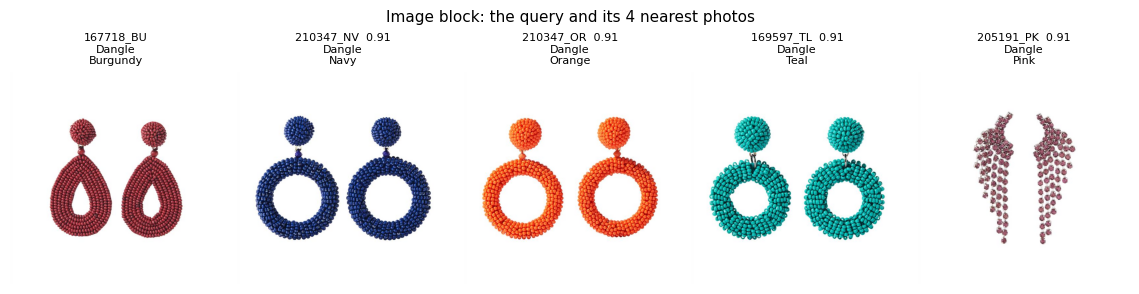

In [14]:
image_m = normalise_rows(image_raw)
print(f"{(np.abs(image_m).sum(1) > 0).sum():,} trusted photos x {image_m.shape[1]} numbers")

def show(keys, title, scores=None):
    rows = items.set_index(KEY).loc[list(keys)]
    fig, axes = plt.subplots(1, len(rows), figsize=(2.3 * len(rows), 2.9))
    for n, (ax, (k, r)) in enumerate(zip(np.atleast_1d(axes), rows.iterrows())):
        if r["img_trusted"]:
            ax.imshow(Image.open(IMG_DIR / r["img_file"]).convert("RGB"))
        else:
            ax.text(0.5, 0.5, "no trusted photo", ha="center", color="#999")
        extra = "" if scores is None or n == 0 else f"  {scores[n - 1]:.2f}"
        ax.set_title(f"{k}{extra}\n{r['GFS_DES_EN']}\n{r['CLR_DES']}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title, fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()

q = items.index[items[KEY] == "167718_BU"][0]            # the example of the brief
top, s = neighbours(image_m, q)
show([items[KEY].iat[q]] + items[KEY].iloc[top].tolist(), "Image block: the query and its 4 nearest photos", s)

## 8. Colour palette block

CLIP sees shape and style more than exact colours, and the colour *name* in the data is broad ("Blue" for navy and
turquoise alike). So each trusted photo also gets its **dominant colours**, measured on the pixels:

1. keep the **product pixels**: inside the product box found in Sprint 1, without the near-white background, resized
   to at most 96 px;
2. convert them to **CIELAB**, a colour space where distances match what the eye sees;
3. **k-means** with 4 clusters (k-means++ start, fixed seed): each cluster centre is a dominant colour, its size the
   colour's share; clusters under 5% are dropped;
4. **name** each colour after the nearest of 24 reference colours;
5. the **palette vector**: the shares summed per colour name, normalised. Two products both "mostly gold and white"
   get a high dot product.

In [15]:
NAMED = {
    "black": (25, 25, 25), "white": (245, 245, 242), "grey": (128, 128, 128), "silver": (190, 190, 195),
    "gold": (205, 170, 90), "beige": (222, 203, 170), "camel": (190, 140, 85), "brown": (110, 70, 40),
    "red": (200, 35, 40), "burgundy": (115, 25, 45), "pink": (240, 150, 175), "fuchsia": (215, 45, 140),
    "orange": (240, 130, 45), "yellow": (245, 215, 55), "green": (45, 150, 75), "khaki": (120, 120, 65),
    "mint": (165, 220, 190), "teal": (10, 120, 120), "turquoise": (60, 195, 200), "light blue": (155, 195, 230),
    "blue": (45, 85, 190), "navy": (28, 38, 80), "purple": (110, 55, 150), "lilac": (190, 165, 220),
}
NAMES = list(NAMED)

def rgb_to_lab(rgb):
    c = np.asarray(rgb, dtype=np.float64) / 255.0
    c = np.where(c > 0.04045, ((c + 0.055) / 1.055) ** 2.4, c / 12.92)
    m = np.array([[0.4124564, 0.3575761, 0.1804375], [0.2126729, 0.7151522, 0.0721750], [0.0193339, 0.1191920, 0.9503041]])
    xyz = c @ m.T / np.array([0.95047, 1.0, 1.08883])
    f = np.where(xyz > (6 / 29) ** 3, np.cbrt(xyz), xyz / (3 * (6 / 29) ** 2) + 4 / 29)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

NAMED_LAB = rgb_to_lab(np.array(list(NAMED.values())))

def kmeans(x, k, iters=20, seed=0):
    rng = np.random.default_rng(seed)
    k = min(k, len(np.unique(x, axis=0)))
    centres = [x[rng.integers(len(x))]]
    for _ in range(1, k):                                   # k-means++: spread the starting centres
        d = np.min(((x[:, None] - np.array(centres)[None]) ** 2).sum(-1), axis=1)
        centres.append(x[rng.choice(len(x), p=d / d.sum())])
    c = np.array(centres)
    for _ in range(iters):
        labels = ((x[:, None] - c[None]) ** 2).sum(-1).argmin(1)
        new = np.array([x[labels == j].mean(0) if (labels == j).any() else c[j] for j in range(k)])
        if np.allclose(new, c):
            break
        c = new
    return c, ((x[:, None] - c[None]) ** 2).sum(-1).argmin(1)

def product_pixels(img, box):
    img = img.convert("RGB")
    if box is not None and len(box) == 4:
        w, h = img.size
        x0, y0, x1, y1 = box
        img = img.crop((int(x0 * w), int(y0 * h), max(int(x0 * w) + 1, int(x1 * w)), max(int(y0 * h) + 1, int(y1 * h))))
    img.thumbnail((96, 96))
    a = np.asarray(img, dtype=np.uint8).reshape(-1, 3)
    keep = a.min(1) < 235                                    # near-white = background
    return a[keep] if keep.mean() > 0.02 else a              # an all-white product would vanish: keep the box

def palette(pixels, k=4):
    lab = rgb_to_lab(pixels)
    centres, labels = kmeans(lab, k)
    share = np.bincount(labels, minlength=len(centres)) / len(labels)
    keep = share >= 0.05
    centres, share = centres[keep], share[keep] / share[keep].sum()
    rgb = np.array([pixels[labels == j].mean(0) for j in np.flatnonzero(keep)])
    names = np.array(NAMES)[((centres[:, None, :] - NAMED_LAB[None]) ** 2).sum(-1).argmin(1)]
    order = np.argsort(-share, kind="stable")
    return [{"lab": centres[j], "rgb": rgb[j] / 255, "share": float(share[j]), "name": str(names[j])} for j in order]

def palette_vector(entries):
    v = np.zeros(len(NAMES), np.float32)
    for e in entries:
        v[NAMES.index(e["name"])] += e["share"]
    return v / np.linalg.norm(v) if np.linalg.norm(v) > 0 else v

In [16]:
masks = pd.read_parquet(EMB_DIR / "masks.parquet").set_index(KEY)
todo = items[items["img_trusted"]]
pal, pal_vec = {}, np.zeros((len(items), len(NAMES)), np.float32)
for i, r in todo.iterrows():                                  # every trusted photo, about 2.5 minutes
    box = masks["box"].get(r[KEY])
    box = None if box is None or (isinstance(box, float) and np.isnan(box)) else list(box)
    with Image.open(IMG_DIR / r["img_file"]) as img:
        pal[r[KEY]] = palette(product_pixels(img, box))
    pal_vec[i] = palette_vector(pal[r[KEY]])
palette_m = normalise_rows(pal_vec)
print(f"palettes: {len(pal):,} photos | colours per photo:",
      pd.Series([len(p) for p in pal.values()]).value_counts().sort_index().to_dict())

palettes: 9,445 photos | colours per photo: {1: 460, 2: 1303, 3: 2208, 4: 5474}


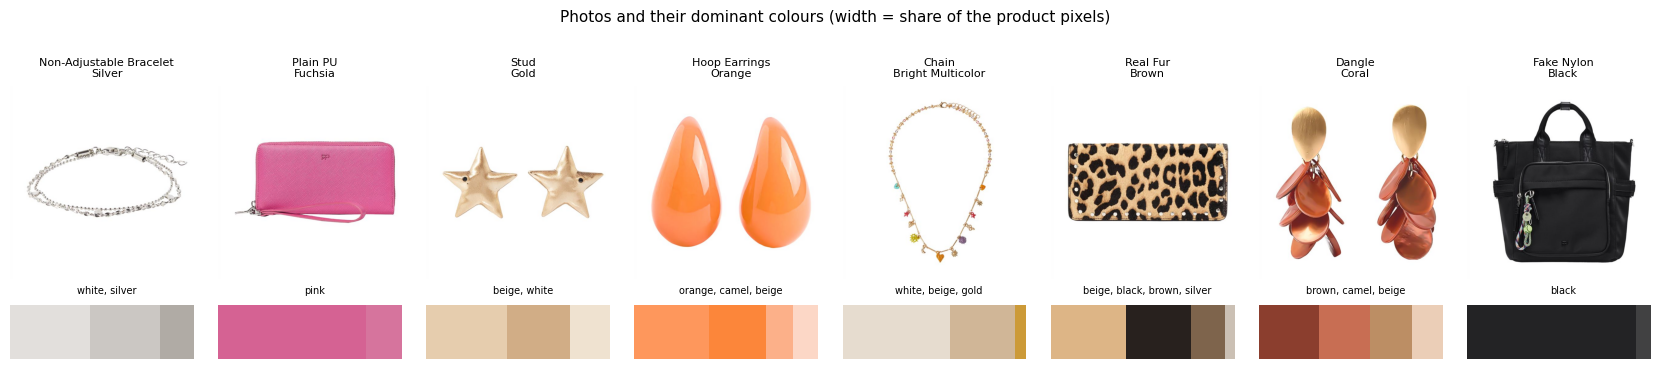

In [17]:
sample = todo[KEY].sample(8, random_state=1).tolist()
fig, axes = plt.subplots(2, len(sample), figsize=(2.1 * len(sample), 3.6), gridspec_kw={"height_ratios": [4, 1]})
for n, k in enumerate(sample):
    r = items.set_index(KEY).loc[k]
    axes[0, n].imshow(Image.open(IMG_DIR / r["img_file"]).convert("RGB"))
    axes[0, n].set_title(f"{r['GFS_DES_EN']}\n{r['CLR_DES']}", fontsize=8)
    x = 0
    for e in pal[k]:
        axes[1, n].barh(0, e["share"], left=x, color=e["rgb"])
        x += e["share"]
    axes[1, n].set_title(", ".join(dict.fromkeys(e["name"] for e in pal[k])), fontsize=7)
    for ax in axes[:, n]:
        ax.axis("off")
fig.suptitle("Photos and their dominant colours (width = share of the product pixels)", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

**Metals look like light neutrals.** On a packshot the largest cluster of a gold item is its highlights: light and
barely saturated, the same as beige or ecru; silver looks white or grey. So the palette does not tell the metal; the
metal comes from `FINISHING`. Palette *similarity* still works, because two gold items get the same palette.

## 9. Colour names measured on the photos

The data has about 100 colour names, many of them shades of one colour ("Navy", "Midnight Blue", "Blue"). As a one-hot
they are as different as "Blue" and "Red". Here each name gets a **reference colour measured on the photos**: the median
LAB of the dominant palette colour of the packshots with that name (at least 5 photos). Two names are then compared by
their distance in LAB, with lightness counting half (a lighter shade of a colour is still that colour):
similarity = exp(−d² / 2τ²), τ = 8.

Multicolour and metallic names get no reference (one colour means nothing for a print, and gold measures as beige).
This table is used later to **explain** matches ("Navy ≈ Midnight Blue"); it is not a score block, because a soft
colour match in the categorical block changed none of the evaluation numbers.

In [18]:
METALLIC = {"Gold", "Light Gold", "Old Gold", "Rose Gold", "Silver", "Old Silver", "Nickel", "Black Nickel", "Copper", "Bronze"}
packshot = masks["packshot"].reindex(items[KEY]).fillna(False).to_numpy(bool)
use = items["img_colour_trusted"].to_numpy() & packshot & items[KEY].isin(pal).to_numpy()
dom = np.stack([pal[k][0]["lab"] for k in items.loc[use, KEY]])     # the largest colour of each photo
ref = pd.DataFrame(dom, columns=["L", "a", "b"]).groupby(items.loc[use, "CLR_DES"].to_numpy()).median()
ref["photos"] = items.loc[use, "CLR_DES"].value_counts()
ref = ref[(ref["photos"] >= 5) & ~ref.index.str.lower().str.contains("multicolor") & ~ref.index.isin(METALLIC)]

lab = ref[["L", "a", "b"]].to_numpy() * np.array([0.5, 1, 1])
sim = np.exp(-((lab[:, None] - lab[None]) ** 2).sum(-1) / (2 * 8.0 ** 2))
names = ref.index.to_numpy()
close = {n: ", ".join(f"{names[j]} {sim[i, j]:.2f}" for j in np.argsort(-sim[i], kind="stable") if j != i and sim[i, j] >= 0.3)
         for i, n in enumerate(names)}
print(f"{len(ref)} colour names with a measured reference colour")
pd.DataFrame({"photos": ref["photos"], "closest names": pd.Series(close)}).loc[
    lambda d: d.index.isin(["Navy", "Blue", "Turquoise", "Beige", "Ecru", "Burgundy", "Khaki", "Pink"])]

64 colour names with a measured reference colour


C:\Users\manue\AppData\Local\Temp\ipykernel_30000\4230802550.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  packshot = masks["packshot"].reindex(items[KEY]).fillna(False).to_numpy(bool)


,photos,closest names
Beige,212,"Skin 0.85, Pearl 0.78, Ecru 0.77, Nude 0.70, I..."
Blue,343,"Blue Jeans 0.87, Indigo 0.38, Light Blue 0.33"
Burgundy,147,"Wine 0.77, Aubergine 0.64"
Ecru,515,"Pearl 0.98, Ivory 0.97, Off White 0.93, Skin 0..."
Khaki,262,"Forest Green 0.92, Brown 0.53, Dark Green 0.43..."
Navy,127,"Midnight Blue 0.87, Dark Grey 0.74, Anthracite..."
Pink,154,Mauve 0.33
Turquoise,62,Aquamarine 0.79


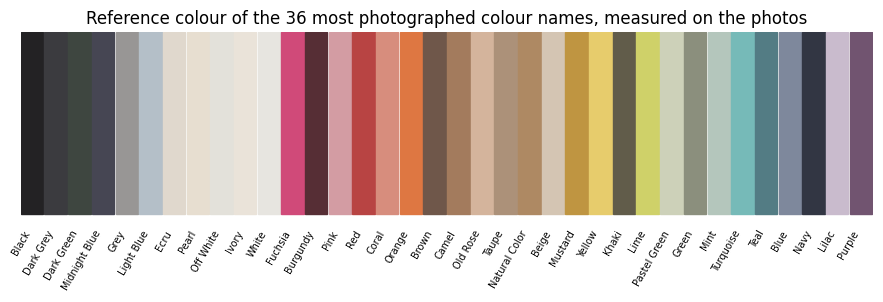

In [19]:
def lab_to_rgb(L, a, b):
    fy = (L + 16) / 116
    f = np.array([fy + a / 500, fy, fy - b / 200])
    xyz = np.where(f > 6 / 29, f ** 3, 3 * (6 / 29) ** 2 * (f - 4 / 29)) * np.array([0.95047, 1.0, 1.08883])
    m = np.array([[3.2404542, -1.5371385, -0.4985314], [-0.9692660, 1.8760108, 0.0415560], [0.0556434, -0.2040259, 1.0572252]])
    c = np.clip(m @ xyz, 0, 1)
    return np.where(c > 0.0031308, 1.055 * c ** (1 / 2.4) - 0.055, 12.92 * c)

top = ref.sort_values("photos", ascending=False).head(36)
chroma = np.hypot(top["a"], top["b"])
top = top.assign(order=np.where(chroma < 8, -1000 + top["L"], np.degrees(np.arctan2(top["b"], top["a"])) % 360)).sort_values("order")  # neutrals first, then by hue
fig, ax = plt.subplots(figsize=(11, 2.6))
for n, (name, r) in enumerate(top.iterrows()):
    ax.add_patch(plt.Rectangle((n, 0), 0.95, 1, color=lab_to_rgb(r.L, r.a, r.b)))
    ax.text(n + 0.47, -0.08, name, rotation=60, ha="right", va="top", fontsize=7)
ax.set_xlim(0, len(top))
ax.set_ylim(-0.1, 1)
ax.axis("off")
ax.set_title("Reference colour of the 36 most photographed colour names, measured on the photos")
plt.show()

## 10. The blocks side by side

Six blocks, one per kind of information, all with the same rules (rows of length 1, missing = zeros):

In [20]:
blocks = {"categorical": cat_m, "composition": comp, "numeric": num_m, "text": text_m, "image": image_m, "palette": palette_m}
pd.DataFrame({name: {"numbers per product": m.shape[1], "products with the block": int((np.abs(m).sum(1) > 0).sum()),
                     "share": (np.abs(m).sum(1) > 0).mean()} for name, m in blocks.items()}).T.style.format({"share": "{:.1%}"})

,numbers per product,products with the block,share
categorical,1624.000000,10555.000000,100.0%
composition,95.000000,10554.000000,100.0%
numeric,79.000000,10555.000000,100.0%
text,384.000000,10555.000000,100.0%
image,512.000000,9445.000000,89.5%
palette,24.000000,9445.000000,89.5%


Each block finds **different** neighbours for the same product, which is why they are combined. For the example of the
brief, the best match of each block, and *why* (the attributes behind the categorical score):

In [21]:
rows = []
for name, m in blocks.items():
    top, s = neighbours(m, q, k=1)
    j = top[0]
    rows.append({"block": name, "best match": items[KEY].iat[j], "score": round(float(s[0]), 2),
                 "sub-family": items["GFS_DES_EN"].iat[j], "colour": items["CLR_DES"].iat[j],
                 "price": items["PRICE_BASE_W_VAT"].iat[j]})
r = items.iloc[q]
print(f"query {r[KEY]}: {r['GFS_DES_EN']}, {r['CLR_DES']}, {r['FINISHING']}, {r['PRICE_BASE_W_VAT']} €")
pd.DataFrame(rows).set_index("block")

query 167718_BU: Dangle, Burgundy, Golden, 8.99 €


,best match,score,sub-family,colour,price
block,,,,,
categorical,210347_NV,0.89,Dangle,Navy,8.99
composition,169607_IG,1.00,Dangle,Indigo,8.99
numeric,203374_NV,1.00,Stud,Navy,8.99
text,210295_BU,0.99,Dangle,Burgundy,5.99
image,210347_NV,0.91,Dangle,Navy,8.99
palette,209725_BU,1.00,Fan,Burgundy,12.99


In [22]:
top, s = neighbours(cat_m, q, k=4)
for j, score in zip(top, s):
    print(f"{items[KEY].iat[j]}  score {score:.2f}  =", shared_attributes(cat_m, cat_attrs, q, j))

210347_NV  score 0.89  = {'GFA': 0.162, 'GFS': 0.162, 'CATEGORY_MATRIX': 0.081, 'FINISHING': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'FINISH_FAMILY': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
1713311BU  score 0.86  = {'GFA': 0.162, 'GFS': 0.162, 'CLR_DES': 0.108, 'CATEGORY_MATRIX': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
214234_BU  score 0.86  = {'GFA': 0.162, 'GFS': 0.162, 'CLR_DES': 0.108, 'CATEGORY_MATRIX': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
215109_BU  score 0.86  = {'GFA': 0.162, 'GFS': 0.162, 'CLR_DES': 0.108, 'CATEGORY_MATRIX': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027,

The categorical score of each neighbour is the sum of the attributes they share: this is how the final system will
**explain** a match. The next sections combine the six blocks into one score.


## 11. The model: one score from the six blocks

The similarity of a candidate *c* to a query *q* is a **weighted mean of the block similarities**:

score(q, c) = Σ_b w_b · sim_b(q, c) / Σ_b w_b, over the blocks *b* that **both** products have.

- sim_b is the dot product of the two rows of block *b* (section 1), so every part is between 0 and 1.
- A product without a trusted photo has no `image` or `palette` row. It is then scored on its other blocks, with
  the weights rescaled to sum to 1: a wrong photo can never make two products similar, and every product still gets
  matches. The `palette` block also needs a photo whose **colour** was checked in the review (`img_colour_trusted`).
- Each block's share of the score, w_b · sim_b / Σ w_b, is its **contribution**: the contributions add up to the
  score, and they are what the final system shows to explain a match ("62% from the photo, 25% from the family").

**Candidates.** Only products of the **same category** (`CAT_DES_EN`: a bag is never proposed for a ring), never the
product itself, and never another colour of the **same model** (`PROD_REF` or `PROD_REF_EQUIV`): those are trivially
similar and a buyer already knows them. Scores are rounded to 6 decimals and ties go to the lower key, so every
computer gets the same list.

The **weights** are what this sprint has to choose. The first ones were set by judgement: the photo and the
categorical attributes matter most, the four smaller blocks add detail.

In [23]:
palette_m[~items["img_colour_trusted"].to_numpy()] = 0
blocks["palette"] = palette_m
BLOCKS = ["image", "categorical", "text", "composition", "palette", "numeric"]
W_JUDGEMENT = {"image": 0.3, "categorical": 0.3, "text": 0.1, "composition": 0.1, "palette": 0.1, "numeric": 0.1}

has = {b: (np.abs(m).sum(1) > 0).astype(np.float32) for b, m in blocks.items()}
MODEL_CODES = [items[c].astype("string").fillna("").to_numpy(object) for c in ["PROD_REF", "PROD_REF_EQUIV"]]
CATEGORY_POOLS = [np.asarray(ix) for _, ix in sorted(items.groupby("CAT_DES_EN").indices.items())]

def score_matrix(w, qs, cs):
    """Scores of the queries qs (rows) against the candidates cs (columns): weights rescaled pair by pair."""
    num = np.zeros((len(qs), len(cs)), np.float32)
    den = np.zeros_like(num)
    for b, wb in w.items():
        if wb > 0:
            both = np.outer(has[b][qs], has[b][cs]) * np.float32(wb)
            num += both * (blocks[b][qs] @ blocks[b][cs].T)
            den += both
    return np.divide(num, den, out=np.zeros_like(num), where=den > 0)

def not_allowed(qs, cs):
    """The query itself and the other colours of its model."""
    out = qs[:, None] == cs[None, :]
    for v in MODEL_CODES:
        out |= (v[qs][:, None] == v[cs][None, :]) & (v[qs][:, None] != "")
    return out

def top_k(w, queries=None, k=10):
    """The k best candidates of every query (or only of `queries`, row numbers): one row per (query, rank)."""
    wanted = np.ones(len(items), bool) if queries is None else np.isin(np.arange(len(items)), queries)
    out = []
    for pool in CATEGORY_POOLS:
        qs_all = pool[wanted[pool]]
        for start in range(0, len(qs_all), 1024):              # 1,024 queries at a time keeps the memory small
            qs = qs_all[start:start + 1024]
            s = np.round(score_matrix(w, qs, pool).astype(np.float64), 6)
            s[not_allowed(qs, pool)] = -np.inf
            order = np.argsort(-s, axis=1, kind="stable")[:, :k]  # the pool is in key order: ties go to the lower key
            best = np.take_along_axis(s, order, axis=1)
            r, c = np.nonzero(np.isfinite(best))
            out.append(pd.DataFrame({"q": qs[r], "rank": c + 1, "c": pool[order[r, c]], "score": best[r, c]}))
    return pd.concat(out, ignore_index=True)

def contributions(w, i, j):
    """Each block's share of the score of the pair (i, j); the shares add up to the score."""
    used = [b for b in BLOCKS if w[b] > 0 and has[b][i] and has[b][j]]
    total = sum(w[b] for b in used)
    return {b: w[b] * float(blocks[b][i] @ blocks[b][j]) / total for b in used}

r = items.iloc[q]
print(f"query {r[KEY]}: {r['GFS_DES_EN']}, {r['CLR_DES']}, {r['PRICE_BASE_W_VAT']} € | weights set by judgement")
first = top_k(W_JUDGEMENT, [q], k=4)
pd.DataFrame([{"rank": t.rank, "candidate": items[KEY].iat[t.c], "score": t.score,
               **{b: round(v, 3) for b, v in contributions(W_JUDGEMENT, q, t.c).items()}} for t in first.itertuples()]).set_index("rank")

query 167718_BU: Dangle, Burgundy, 8.99 € | weights set by judgement


,candidate,score,image,categorical,text,composition,palette,numeric
rank,,,,,,,,
1,210347_NV,0.822889,0.273,0.268,0.098,0.083,0.001,0.100
2,181831_BL,0.800303,NaN,0.378,0.156,0.134,NaN,0.131
3,214234_BU,0.793779,0.266,0.259,0.097,0.000,0.099,0.072
4,215109_BU,0.784455,0.228,0.259,0.098,0.055,0.044,0.100


## 12. How to judge a model without a right answer

Nobody has labelled which products are "similar", so the model is judged by **three families of signals**, each
measured on the top 4 (the brief asks for at least 4):

| Signal | Family | What it measures |
|---|---|---|
| `hit@4` | catalogue | the query has a **known similar** product (same family › sub-family, `THEME` and `CLR_DES`, another model) and it is in the top 4 |
| `same_subfamily`, `same_colour`, `same_finishing`, `same_material` | catalogue | share of the top 4 that agree with the query (pairs where both have the value; the original values, not the filled ones) |
| `visual@4` | visual | share of the top 4 among the query's 20 nearest **photos** (same category, other models) |
| `sales_corr` | commercial | rank correlation (Spearman) between the query's sales percentile in its category and the mean of its top 4. Sales are **not** used by the model, so this is an independent check: similar products sell alike |
| `price_ratio` | – | median of the higher / lower price in the top 4 (1.00 = same price) |

The **objective** is the mean of the three families (catalogue = mean of its five signals). Each family favours one
block: catalogue the categorical block, visual the image block. So no single signal decides; section 13 uses this.

**No overfitting.** The models (`PROD_REF`) are split in two halves at random (fixed seed): the weights are chosen on
the **tuning half**, and every number reported is measured on the **test half**. A **random** choice of 4 products of
the same category is the floor.

In [24]:
refs = np.sort(items["PROD_REF"].astype(str).unique())
tune_refs = set(np.random.default_rng(0).permutation(refs)[: len(refs) // 2])
tune = items["PROD_REF"].astype(str).isin(tune_refs).to_numpy()
TUNE_Q, TEST_Q = np.flatnonzero(tune), np.flatnonzero(~tune)

# "known similar": same category › family › sub-family, theme and colour, shared by at least two models
GROUP_COLS = ["CAT_DES_EN", "GFA_DES_EN", "GFS_DES_EN", "THEME", "CLR_DES"]
full = items[GROUP_COLS].notna().all(axis=1)
gid = pd.Series(-1, index=items.index)
gid[full] = items.loc[full].groupby(GROUP_COLS, sort=True).ngroup()
models_in_group = items.loc[full].groupby(gid[full])["PROD_REF"].transform("nunique")
gid[full & models_in_group.reindex(items.index).lt(2)] = -1
gid = gid.to_numpy()

# the 20 nearest photos of every product with a trusted photo
photo = has["image"] > 0
visual_pool = {}
for pool in CATEGORY_POOLS:
    pool = pool[photo[pool]]
    for start in range(0, len(pool), 1024):
        qs = pool[start:start + 1024]
        s = np.round((image_m[qs] @ image_m[pool].T).astype(np.float64), 6)
        s[not_allowed(qs, pool)] = -np.inf
        for qi, row in zip(qs, np.argsort(-s, axis=1, kind="stable")[:, :20]):
            visual_pool[qi] = set(pool[row])

material_csv = items["MATERIAL"].where(~items[KEY].isin(filled.loc[filled["column"] == "MATERIAL", KEY]))
AGREE = {"same_family": items["GFA_DES_EN"],
         "same_subfamily": items["GFA_DES_EN"].astype("string") + " › " + items["GFS_DES_EN"].astype("string"),
         "same_colour": items["CLR_DES"], "same_finishing": items["FINISHING"], "same_material": material_csv}
AGREE = {n: v.astype("string").to_numpy(object, na_value=None) for n, v in AGREE.items()}
sales = items["sales_pct_in_cat"].to_numpy(float)
price = items["PRICE_BASE_W_VAT"].to_numpy(float)

def evaluate(nb):
    """Every signal for one set of neighbours (columns q, rank, c)."""
    top = nb[nb["rank"] <= 4]
    qi, ci = top["q"].to_numpy(), top["c"].to_numpy()
    m = {}
    known = gid[qi] >= 0
    m["hit@4"] = pd.Series(known & (gid[qi] == gid[ci])).groupby(qi).any()[pd.Series(known).groupby(qi).first()].mean()
    for name, v in AGREE.items():
        both = pd.notna(v[qi]) & pd.notna(v[ci])
        m[name] = (v[qi][both] == v[ci][both]).mean()
    m["visual@4"] = np.mean([c in visual_pool[a] for a, c in zip(qi, ci) if a in visual_pool and c in visual_pool])
    per_q = pd.DataFrame({"own": sales[qi], "nb": sales[ci]}).groupby(qi).agg(own=("own", "first"), nb=("nb", "mean")).dropna()
    m["sales_corr"] = per_q["own"].rank().corr(per_q["nb"].rank())
    m["price_ratio"] = np.nanmedian(np.maximum(price[qi], price[ci]) / np.minimum(price[qi], price[ci]))
    m["catalogue"] = np.mean([m[s] for s in ["hit@4", "same_subfamily", "same_colour", "same_finishing", "same_material"]])
    m["visual"], m["commercial"] = m["visual@4"], m["sales_corr"]
    m["objective"] = np.mean([m["catalogue"], m["visual"], m["commercial"]])
    return m

def random_top4(queries, seed=0):
    rng, rows = np.random.default_rng(seed), []
    for pool in CATEGORY_POOLS:
        for qi in queries[np.isin(queries, pool)]:
            allowed = pool[~not_allowed(np.array([qi]), pool)[0]]
            rows += [(qi, r + 1, ci) for r, ci in enumerate(rng.choice(allowed, size=4, replace=False))]
    return pd.DataFrame(rows, columns=["q", "rank", "c"])

SHOW = ["hit@4", "same_family", "same_subfamily", "same_colour", "same_finishing", "same_material", "visual@4",
        "sales_corr", "price_ratio", "catalogue", "objective"]
PCT = {c: "{:.0%}" for c in SHOW if c not in ("sales_corr", "price_ratio", "objective")} | {
    "sales_corr": "{:.3f}", "price_ratio": "{:.2f}", "objective": "{:.3f}"}
results = pd.DataFrame({"random (same category)": evaluate(random_top4(TEST_Q)),
                        "weights set by judgement": evaluate(top_k(W_JUDGEMENT, TEST_Q, k=4))}).T
print(f"tuning half: {len(TUNE_Q):,} queries | test half: {len(TEST_Q):,} queries, "
      f"{(gid[TEST_Q] >= 0).sum():,} of them with a known similar product")
results[SHOW].style.format(PCT)

tuning half: 5,263 queries | test half: 5,292 queries, 2,317 of them with a known similar product


,hit@4,same_family,same_subfamily,same_colour,same_finishing,same_material,visual@4,sales_corr,price_ratio,catalogue,objective
random (same category),1%,26%,8%,8%,37%,17%,1%,0.001,1.33,14%,0.052
weights set by judgement,87%,96%,85%,57%,80%,75%,37%,0.623,1.00,77%,0.586


## 13. Choosing the weights, step 1: tuned on the signals

A blind search on the objective moves almost all the weight to the photo: `visual@4` rises and the material and
colour agreement fall. That is a **trade-off between families**, and the signals cannot decide it (each one favours
its own block). So the search below only accepts a change that is better without being worse:

- **coordinate search** on the tuning half: each block weight in turn is multiplied by 0, 0.5, 1.5 and 2;
- a change is kept only if the objective rises by at least 0.005 **and** no single signal (`hit@4`, the four
  agreements, `visual@4`, `sales_corr`) drops by more than 0.01;
- at most two passes over the six blocks.

In [25]:
GUARDED = ["hit@4", "same_subfamily", "same_colour", "same_finishing", "same_material", "visual@4", "sales_corr"]

def normalised(w):
    total = sum(w.values())
    return {b: round(v / total, 4) for b, v in w.items()}

def better(new, old):
    return new["objective"] >= old["objective"] + 0.005 and all(new[s] >= old[s] - 0.01 for s in GUARDED)

best = dict(W_JUDGEMENT)
best_m = evaluate(top_k(best, TUNE_Q, k=4))
log = [{"change": "start", **normalised(best), "objective": best_m["objective"]}]
for _ in range(2):
    improved = False
    for b in sorted(best):
        for f in (0.0, 0.5, 1.5, 2.0):
            trial = {**best, b: best[b] * f if best[b] > 0 else (0.1 if f > 1 else 0.0)}
            if trial == best:
                continue
            m = evaluate(top_k(trial, TUNE_Q, k=4))
            if better(m, best_m):
                best, best_m, improved = trial, m, True
                log.append({"change": f"{b} ×{f:g}", **normalised(best), "objective": m["objective"]})
    if not improved:
        break
W_TUNED = normalised(best)
pd.DataFrame(log).style.format({"objective": "{:.3f}", **{b: "{:.3f}" for b in BLOCKS}})

,change,image,categorical,text,composition,palette,numeric,objective
0,start,0.300,0.300,0.100,0.100,0.100,0.100,0.587
1,categorical ×1.5,0.261,0.391,0.087,0.087,0.087,0.087,0.593
2,image ×1.5,0.346,0.346,0.077,0.077,0.077,0.077,0.600
3,palette ×0.5,0.360,0.360,0.080,0.080,0.040,0.080,0.605


The search raises the photo and the categorical attributes together (0.60 → 0.72 of the weight) and halves the
palette, which mostly repeats what the photo shows. How much the **photo** should weigh against the attributes is
still open. Moving only the image weight (the other blocks keep their proportions) shows the trade-off on the test
half:

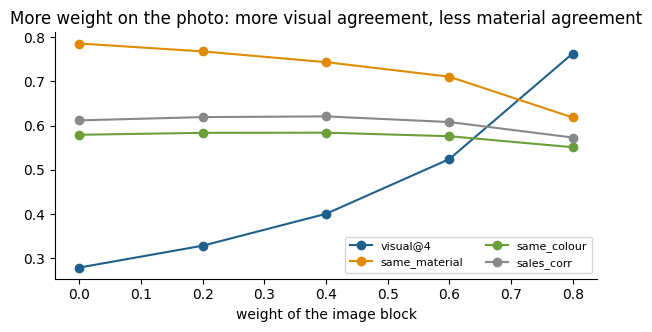

In [26]:
def with_image(w, w_image):
    rest = {b: v for b, v in w.items() if b != "image"}
    return {"image": w_image, **{b: (1 - w_image) * v / sum(rest.values()) for b, v in rest.items()}}

sweep = pd.DataFrame({w_img: evaluate(top_k(with_image(W_TUNED, w_img), TEST_Q, k=4)) for w_img in (0.0, 0.2, 0.4, 0.6, 0.8)}).T
sweep.index.name = "image weight"
fig, ax = plt.subplots(figsize=(7, 3.2))
for col, colour in [("visual@4", "#1f5f8b"), ("same_material", "#e08a00"), ("same_colour", "#6a9f3a"), ("sales_corr", "#888")]:
    ax.plot(sweep.index, sweep[col], "o-", color=colour, label=col)
ax.set_xlabel("weight of the image block")
ax.set_title("More weight on the photo: more visual agreement, less material agreement")
ax.legend(fontsize=8, ncol=2)
plt.show()

## 14. Choosing the weights, step 2: learned from the team's judgement

The trade-off was decided by **people**. Each of the five members sorted products in a small browser app (Sprint 2
work, done outside this notebook; the answers are saved and loaded here):

1. **140 queries**, chosen at random per category (16 with a trusted photo and 4 without).
2. For each query a **fixed pool** of about 9 candidates: the top 5 at image weights 0, 0.3 and 0.6, plus 2 random
   products of the category. The pool never depends on the weights being learned, so there is no feedback loop.
3. The candidates are shown **shuffled and blind** (no score, no source). The member drags them into *Similar*
   (best first) or *Not similar*.
4. **10 queries** are sorted by every member, to measure how much people agree; **20%** of the queries are kept
   apart (held out) and never used for learning.

`outputs/phase4/feedback_pool.json` has the pools, with the six block similarities of every candidate;
`outputs/phase4/feedback_<n>.jsonl` has each member's answers (the latest answer to a query counts).

In [27]:
fb_pool = json.loads((ROOT / "outputs" / "phase4" / "feedback_pool.json").read_text(encoding="utf-8"))
latest = {}
for path in sorted((ROOT / "outputs" / "phase4").glob("feedback_*.jsonl")):
    for line in path.read_text(encoding="utf-8").splitlines():
        if line.strip():
            a = json.loads(line)
            latest[(a["member"], a["query"])] = a
answers = [latest[k] for k in sorted(latest)]

pair_row, sims = {}, []
for pq in fb_pool["queries"]:
    for cand in pq["candidates"]:
        pair_row[(pq["query"], cand["key"])] = len(sims)
        sims.append([np.nan if cand["sim"][b] is None else cand["sim"][b] for b in BLOCKS])
S = np.asarray(sims, float)
H = np.isfinite(S).astype(float)          # 1 where both products have the block
S = np.nan_to_num(S)
held_out = {pq["query"] for pq in fb_pool["queries"] if pq["holdout"]}

def preferences(ans):
    """Every "similar" product beats the similar ones below it and every "not similar" one: (winner, loser) rows."""
    win, lose = [], []
    for a in ans:
        sim = [pair_row[(a["query"], c)] for c in a["similar"]]
        nots = [pair_row[(a["query"], c)] for c in a["not"]]
        for i, x in enumerate(sim):
            for y in sim[i + 1:] + nots:
                win.append(x)
                lose.append(y)
    return np.asarray(win, int), np.asarray(lose, int)

train = [a for a in answers if a["query"] not in held_out]
test = [a for a in answers if a["query"] in held_out]
win, lose = preferences(train)
print(f"{len(answers)} sorted queries by members {sorted({a['member'] for a in answers})} | "
      f"learning: {len({a['query'] for a in train})} queries, {len(win):,} preferences | held out: {len(test)} answers")

138 sorted queries by members [1, 2, 3, 4, 5] | learning: 79 queries, 3,330 preferences | held out: 24 answers


**Bradley–Terry model.** The probability that a member prefers candidate *a* to *b* is modelled as
σ(β · (score(a) − score(b))), where σ is the logistic function and *score* is exactly the model of section 11, with
weights w = softmax(θ) (positive, summing to 1). The weights that make the members' preferences most likely are found
by gradient descent (Adam, 1,500 fixed steps: deterministic). A **prior** pulls θ towards the weights of step 1
(normal, sd 0.5 on the log-weights), so a weight moves by a factor of about 1.6 only with clear evidence.

In [28]:
W0 = np.array([W_TUNED[b] for b in BLOCKS])
PRIOR_SD, BETA0 = 0.5, 20.0

def model_scores(w, s=S, h=H):
    den = h @ w
    return np.divide((h * s) @ w, den, out=np.zeros(len(s)), where=den > 0)

def softmax(t):
    e = np.exp(t - t.max())
    return e / e.sum()

def loss_and_grad(p, theta0):
    theta, gamma = p[:-1], p[-1]
    w, beta = softmax(theta), np.exp(gamma)
    den = H @ w
    sc = np.divide((H * S) @ w, den, out=np.zeros(len(S)), where=den > 0)
    d = sc[win] - sc[lose]
    loss = np.logaddexp(0, -beta * d).sum() + ((theta - theta0) ** 2).sum() / (2 * PRIOR_SD ** 2) + (gamma - np.log(BETA0)) ** 2 / 2
    g_d = -beta / (1 + np.exp(np.clip(beta * d, -50, 50)))
    ds_dw = np.divide(H * S - sc[:, None] * H, den[:, None], out=np.zeros_like(S), where=den[:, None] > 0)
    g_w = (g_d[:, None] * (ds_dw[win] - ds_dw[lose])).sum(0)
    g_theta = w * (g_w - w @ g_w) + (theta - theta0) / PRIOR_SD ** 2
    g_gamma = (g_d * d).sum() + (gamma - np.log(BETA0))
    return loss, np.append(g_theta, g_gamma)

theta0 = np.log(W0 / W0.sum())
p, m1, m2 = np.append(theta0, np.log(BETA0)), np.zeros(len(BLOCKS) + 1), np.zeros(len(BLOCKS) + 1)
for t in range(1, 1501):
    _, g = loss_and_grad(p, theta0)
    m1, m2 = 0.9 * m1 + 0.1 * g, 0.999 * m2 + 0.001 * g ** 2
    p -= 0.05 * (m1 / (1 - 0.9 ** t)) / (np.sqrt(m2 / (1 - 0.999 ** t)) + 1e-8)
W_LEARNED = softmax(p[:-1])

def held_out_accuracy(w):
    """Share of the held-out preferences that the weights order the right way."""
    hw, hl = preferences(test)
    sc = model_scores(w)
    return (sc[hw] > sc[hl]).mean(), len(hw)

acc0, n_pairs = held_out_accuracy(W0)
acc1, _ = held_out_accuracy(W_LEARNED)
print(f"held-out preferences ({n_pairs}) ordered right: step 1 weights {acc0:.1%} -> learned {acc1:.1%}")
pd.DataFrame({"step 1 (signals)": W0, "learned (team)": W_LEARNED}, index=BLOCKS).T.round(3)

held-out preferences (699) ordered right: step 1 weights 72.8% -> learned 75.3%


,image,categorical,text,composition,palette,numeric
step 1 (signals),0.360,0.360,0.080,0.080,0.040,0.080
learned (team),0.618,0.247,0.067,0.028,0.016,0.024


The team gives the **photo** much more weight (0.36 → 0.62) and the composition and numeric blocks less. How far can
that be trusted? On the 10 queries everybody sorted, two members order a pair of candidates the same way only about
70% of the time: the learned weights cannot agree with "the team" more than its members agree with each other.

In [29]:
same = total = 0
by_query = {}
for a in answers:
    by_query.setdefault(a["query"], []).append({c: i for i, c in enumerate(a["similar"])} | {c: len(a["similar"]) for c in a["not"]})
for ranks in by_query.values():
    for i in range(len(ranks)):
        for j in range(i + 1, len(ranks)):
            cands = sorted(ranks[i])
            for x in range(len(cands)):
                for y in range(x + 1, len(cands)):
                    s1 = np.sign(ranks[i][cands[x]] - ranks[i][cands[y]])
                    s2 = np.sign(ranks[j][cands[x]] - ranks[j][cands[y]])
                    if s1 and s2:
                        same, total = same + (s1 == s2), total + 1
print(f"pairs ordered by two members: {total:,}, in the same order: {same / total:.0%}")

pairs ordered by two members: 2,371, in the same order: 70%


**The final weights: a blend.** The fully learned weights order the most held-out preferences right, but they lose
material agreement and pull the prices of the matches apart. So the model uses a point **part of the way** from the
step 1 weights to the learned ones. Each blend is checked on both sides: the team's held-out preferences and the
signals on the test half.

In [30]:
blend_rows = {}
for share in (0.0, 0.25, 0.5, 0.75, 1.0):
    w = dict(zip(BLOCKS, (1 - share) * W0 + share * W_LEARNED))
    m = evaluate(top_k(w, TEST_Q, k=4))
    blend_rows[f"{share:.0%}"] = {"image weight": w["image"], "held-out preferences right": held_out_accuracy(np.array(list(w.values())))[0],
                                  "same_material": m["same_material"], "visual@4": m["visual@4"],
                                  "sales_corr": m["sales_corr"], "price_ratio": m["price_ratio"]}
blends = pd.DataFrame(blend_rows).T
blends.index.name = "way to the learned weights"
blends.style.format({"image weight": "{:.2f}", "held-out preferences right": "{:.1%}", "same_material": "{:.1%}",
                     "visual@4": "{:.1%}", "sales_corr": "{:.3f}", "price_ratio": "{:.2f}"})

,image weight,held-out preferences right,same_material,visual@4,sales_corr,price_ratio
way to the learned weights,,,,,,
0%,0.36,72.8%,74.5%,38.5%,0.623,1.00
25%,0.42,73.8%,73.9%,41.4%,0.618,1.00
50%,0.49,73.4%,72.1%,45.0%,0.612,1.00
75%,0.55,74.2%,69.7%,50.0%,0.603,1.07
100%,0.62,75.3%,65.6%,55.7%,0.585,1.08


**25%** keeps most of the team's gain at almost no cost to the other signals (the differences between 73% and 75%
are small for about 700 held-out preferences; the material drop beyond 25% is not). These are the weights of the
final model:

In [31]:
W_FINAL = normalised(dict(zip(BLOCKS, 0.75 * W0 + 0.25 * W_LEARNED)))
pd.DataFrame({"set by judgement": W_JUDGEMENT, "step 1 (signals)": W_TUNED, "step 2 (team, 25%)": W_FINAL}).T.round(3)

,image,categorical,text,composition,palette,numeric
set by judgement,0.300,0.300,0.100,0.100,0.100,0.100
step 1 (signals),0.360,0.360,0.080,0.080,0.040,0.080
"step 2 (team, 25%)",0.425,0.332,0.077,0.067,0.034,0.066


## 15. The final model

The top 10 of **every** colourway with the final weights (about 10 seconds), and its evaluation on the test half.

In [32]:
final = top_k(W_FINAL, k=10)
found = final.groupby("q").size().reindex(range(len(items)), fill_value=0)
coverage = pd.DataFrame({"products": items.groupby("CAT_DES_EN").size(),
                         "with a trusted photo": items.groupby("CAT_DES_EN")["img_trusted"].sum(),
                         "fewer than 4 matches": (found < 4).groupby(items["CAT_DES_EN"]).sum()})
print(f"{final['q'].nunique():,} queries x up to 10 matches = {len(final):,} rows")
coverage

10,555 queries x up to 10 matches = 105,550 rows


,products,with a trusted photo,fewer than 4 matches
CAT_DES_EN,,,
Apparel,2259,1869,0
Footwear,435,424,0
Hand Bag,1971,1805,0
Jewellery,4639,4156,0
Wallet,1251,1191,0


In [33]:
results.loc["step 1 (signals)"] = evaluate(top_k(W_TUNED, TEST_Q, k=4))
results.loc["final (team, 25%)"] = evaluate(final[np.isin(final["q"], TEST_Q)])
results[SHOW].style.format(PCT)

,hit@4,same_family,same_subfamily,same_colour,same_finishing,same_material,visual@4,sales_corr,price_ratio,catalogue,objective
random (same category),1%,26%,8%,8%,37%,17%,1%,0.001,1.33,14%,0.052
weights set by judgement,87%,96%,85%,57%,80%,75%,37%,0.623,1.00,77%,0.586
step 1 (signals),91%,98%,90%,58%,84%,74%,39%,0.623,1.00,79%,0.601
"final (team, 25%)",92%,98%,90%,59%,84%,74%,41%,0.618,1.00,80%,0.610


Against random, the final model finds a known similar product for 92% of the queries (random: 1%), agrees with the
query on the sub-family 90% of the time and on the material 74%, and its matches **sell alike** (correlation 0.62),
although sales are not part of the model. Each weighting step improved the objective on the test half, which the
weights never saw.

**Ablations**: what each block adds. The same final weights with one block left out, and each block alone:

In [34]:
abl = {"final": W_FINAL, "tabular only (no photo)": {b: (0.0 if b in ("image", "palette") else w) for b, w in W_FINAL.items()}}
abl |= {f"without {b}": {x: (0.0 if x == b else w) for x, w in W_FINAL.items()} for b in BLOCKS}
abl |= {f"only {b}": {x: float(x == b) for x in BLOCKS} for b in BLOCKS}
ablations = pd.DataFrame({name: evaluate(top_k(w, TEST_Q, k=4)) for name, w in abl.items()}).T
ablations[SHOW].style.format(PCT)

,hit@4,same_family,same_subfamily,same_colour,same_finishing,same_material,visual@4,sales_corr,price_ratio,catalogue,objective
final,92%,98%,90%,59%,84%,74%,41%,0.618,1.00,80%,0.610
tabular only (no photo),91%,99%,92%,56%,85%,78%,26%,0.621,1.00,80%,0.560
without image,92%,99%,92%,59%,85%,79%,28%,0.614,1.00,81%,0.568
without categorical,62%,72%,59%,43%,62%,74%,48%,0.617,1.00,60%,0.567
without text,90%,98%,87%,59%,85%,74%,42%,0.624,1.00,79%,0.612
without composition,94%,99%,92%,62%,85%,55%,43%,0.616,1.00,77%,0.607
without palette,91%,99%,91%,57%,84%,75%,40%,0.621,1.00,80%,0.605
without numeric,91%,99%,92%,62%,85%,76%,44%,0.553,1.11,81%,0.601
only image,39%,68%,42%,39%,54%,28%,100%,0.266,1.20,41%,0.558
only categorical,93%,100%,94%,67%,91%,62%,25%,0.534,1.13,81%,0.533


- **Each block alone** is weaker than the combination. The categorical block alone scores higher on the catalogue
  signals, because those signals are built from its attributes, but its matches look less alike (`visual@4` 25%
  against 41%) and sell less alike (0.53 against 0.62). The image alone matches photos (100% by definition) but agrees
  on the material only 28% of the time.
- **Without the composition** block the material agreement falls from 74% to 55%; **without the numeric** block the
  sales correlation falls to 0.55 and the prices of the matches drift apart. Every block earns its place.
- **Without a photo** (tabular only) the catalogue agreement stays, and `visual@4` falls to 26%: this is the quality
  the products without a trusted photo get.

## 16. Example: the product of the brief, and why each match was chosen

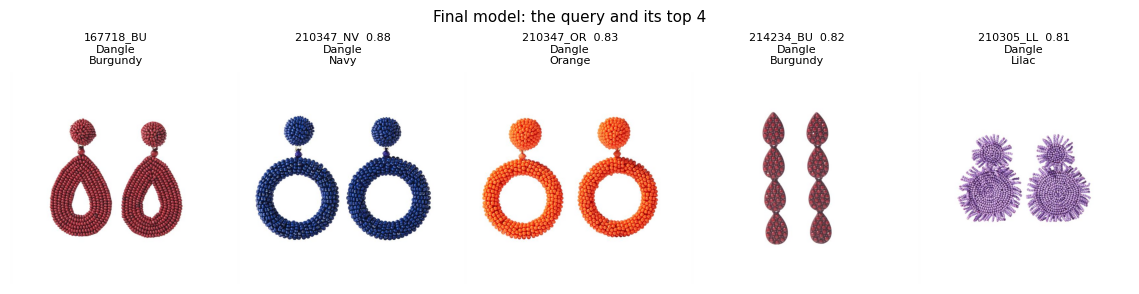

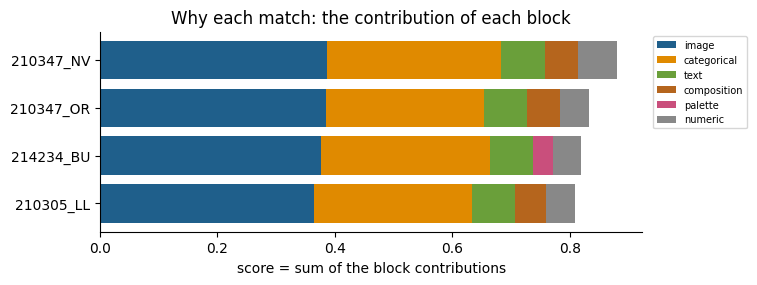

210347_NV: categorical attributes shared = {'GFA': 0.162, 'GFS': 0.162, 'CATEGORY_MATRIX': 0.081, 'FINISHING': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'FINISH_FAMILY': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
210347_OR: categorical attributes shared = {'GFA': 0.162, 'GFS': 0.162, 'CATEGORY_MATRIX': 0.081, 'FINISHING': 0.081, 'CAT': 0.054, 'FINISH_FAMILY': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
214234_BU: categorical attributes shared = {'GFA': 0.162, 'GFS': 0.162, 'CLR_DES': 0.108, 'CATEGORY_MATRIX': 0.081, 'THEME': 0.081, 'CAT': 0.054, 'PRINT_TYPE': 0.054, 'DIMENSION': 0.054, 'CLR_TYPE': 0.027, 'FASHIONTYPE': 0.027, 'PROD_SEG': 0.027, 'NUMBER_OF_UNITS': 0.027}
210305_LL: categorical attributes shared = {'GFA': 0.162, 'GFS': 0.162, 'CATEGORY_MATRIX': 0.081, 'FINISHING': 0.081, 'CAT': 0.054, 'FINISH_FAMIL

In [35]:
top4 = final[(final["q"] == q) & (final["rank"] <= 4)]
show([items[KEY].iat[q]] + items[KEY].iloc[top4["c"]].tolist(), "Final model: the query and its top 4", top4["score"].tolist())
parts = pd.DataFrame([contributions(W_FINAL, q, j) for j in top4["c"]], index=items[KEY].iloc[top4["c"]]).reindex(columns=BLOCKS).fillna(0)
fig, ax = plt.subplots(figsize=(7, 2.6))
left = np.zeros(len(parts))
for b, colour in zip(BLOCKS, ["#1f5f8b", "#e08a00", "#6a9f3a", "#b5651d", "#c94f7c", "#888"]):
    ax.barh(parts.index, parts[b], left=left, color=colour, label=b)
    left += parts[b].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("score = sum of the block contributions")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Why each match: the contribution of each block")
plt.show()
for j in top4["c"]:
    print(f"{items[KEY].iat[j]}: categorical attributes shared =", shared_attributes(cat_m, cat_attrs, q, j))

## Summary

| Block | What it captures | Built |
|---|---|---|
| categorical | family, sub-family, colour name, finishing, theme, … (16 weighted attributes) | here |
| composition | materials, rare ones counting more | here |
| numeric | price within the category, launch date, season | here |
| text | the description's meaning ("Golden Basics" ≈ "Golden Delicates") | sentence model, once |
| image | shape and style of the product crop | CLIP, once |
| palette | the dominant colours of the photo | here (k-means in LAB) |

Also: missing material (apparel) and metal (jewellery) filled only where 5-fold cross-validation shows ≥ 90% precision,
and a reference colour per colour name, measured on the photos, for the explanations.

**Modelling.** score = Σ w_b · sim_b / Σ w_b over the blocks both products have, candidates of the same category and
other models only. The weights were chosen in three steps, each better on the test half:

| Weights | image | categorical | text | composition | palette | numeric | how |
|---|---|---|---|---|---|---|---|
| set by judgement | 0.30 | 0.30 | 0.10 | 0.10 | 0.10 | 0.10 | photo and attributes first |
| step 1 (signals) | 0.36 | 0.36 | 0.08 | 0.08 | 0.04 | 0.08 | guarded coordinate search |
| **final** | **0.42** | **0.33** | **0.08** | **0.07** | **0.03** | **0.07** | Bradley–Terry on 138 sorted queries, 25% of the way |

Every colourway gets at least 4 matches (10 are kept). On the test half the final model finds a known similar product
for 92% of the queries (random 1%), matches the sub-family 90% and the material 74% of the time, and its matches sell
alike (0.62). Each match comes with its block contributions and shared attributes: the base of the explanations.
